# 05 · Feature engineering

[Guide](../README.md) | [Previous](04_Categorical_Encoding.ipynb) | [Next](06_Feature_Selection.ipynb)

## 1. What problem are we solving?

Can useful relationships be expressed more clearly than in the original columns?

## 2. Why does it matter?

A form difference or late-game interaction can be easier for a model to use than separate measurements.

## 3. Key concepts

| Term | Simple meaning |
|---|---|
| Engineered feature | A new column calculated from available inputs, not from the answer. |
| Difference / interaction | Subtract two measurements / combine measurements so their joint effect is visible. |
| Candidate | A plausible idea to test, not a feature guaranteed to help. |
| Leakage | Information unavailable at prediction time sneaks into model training or selection. |
| FunctionTransformer | Put an input-editing function inside a pipeline so the same formulas apply to training and future rows. |
| Pipeline notation | `clone` copies unfitted settings; `step__setting` changes one pipeline setting. Earlier steps stay fixed during a comparison. |

## 4. Intuitive example

Illustrative kick: player form 70%, keeper saves 30%, minute 88, score difference −1, poor pitch. Then `skill_gap = 40`, `late_close_game = 1`, and `poor_pitch_late = 1`. These express form, pressure, and environment hypotheses; only the scored comparison tells us whether they help.

## 5. Methods to compare

| Feature set | Why try it? | Trade-off |
|---|---|---|
| Original inputs | Check whether extra formulas are necessary | May hide useful relationships |
| Form and technique: 6 candidates | Differences, ratios, and curved form effects | Can add redundant measurements |
| Match context: 8 candidates | Timing, score, crowd, and pressure interactions | More hypotheses can add noise |
| Environment: 6 candidates | Pitch/weather combinations and compressed capacity | Some transformations may not help |
| All groups: 20 candidates | Test complementary relationships together | Largest set; selection may remove weak columns |

## 6. What we retained from previous notebooks

| Earlier decision | Choice used here |
|---|---|
| Missing | Drop incomplete training rows |
| Scaling | Robust scaling |
| Encoding | One-hot |

## 7. Setup

**Reusable setup — run this cell, then skip to the lesson.** You do not need to study all these lines now: they load the data and rebuild earlier steps so this notebook works on its own. Revisit the earlier lessons for explanations.

Change `DATA_DIR` for your runtime. The cell starts collapsed where the editor supports it; GitHub may show it expanded. `X` contains inputs; `y` contains known answers. Learned preparation stays inside training folds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)

# Change this one folder on Kaggle or Colab (see the guide).
DATA_DIR = "../data"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("Train:", train.shape, "Test:", test.shape)

# Split train.csv: 80% for training, 20% for a separate validation check.
training_data, validation_data = train_test_split(
    train, test_size=0.20, stratify=train["is_scored"], random_state=2026
)
training_data = training_data.reset_index(drop=True)

# IDs identify rows; they do not describe how a penalty was taken.
id_columns = ["id", "kicker_id", "keeper_id", "match_id"]
X = training_data.drop(columns=id_columns + ["is_scored"])
y = training_data["is_scored"]

from sklearn.base import clone
from sklearn.compose import make_column_selector
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from imblearn import FunctionSampler
from imblearn.pipeline import Pipeline

def remove_incomplete_rows(X, y):
    keep = ~X.isna().any(axis=1)
    return X.loc[keep], y[keep]

numbers = Pipeline([("fill", SimpleImputer(strategy='median')), ("scale", RobustScaler())])
categories = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("numbers", numbers, make_column_selector(dtype_include="number")),
    ("categories", categories, make_column_selector(dtype_exclude="number")),
])

pipeline = Pipeline([
    ("missing_rows", FunctionSampler(func=remove_incomplete_rows, validate=False)),
    ("features", "passthrough"),
    ("prepare", preprocess),
    ("model", LogisticRegression(solver="liblinear", max_iter=1000, random_state=42)),
])

# Each fold trains on two parts and predicts the third, unseen part.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def compare(models, X, y):
    rows = []
    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=["f1", "accuracy", "roc_auc"])
        rows.append([name, scores["test_f1"].mean(), scores["test_f1"].std(),
                     scores["test_accuracy"].mean(), scores["test_roc_auc"].mean()])
    columns = ["method", "F1", "F1 spread", "accuracy", "ROC-AUC"]
    return pd.DataFrame(rows, columns=columns).sort_values("F1", ascending=False)

Train: (20000, 20) Test: (6000, 19)


## 8. Experiments

Run the topic-specific steps below. Saved experimental outputs are retained from the earlier runs; regrouping setup does not create a new evaluation.

### Form and technique: why these six?

| New feature | Formula / reason |
|---|---|
| skill_gap | Kicker form − keeper form: direct comparison |
| foot_advantage | Strong-foot use − weak-foot use: technique preference |
| form_ratio | (Kicker form + 1) / (keeper form + 1): relative strength; +1 avoids division by zero |
| form_interaction | Kicker form × keeper form / 100: their joint level, not only their difference |
| player_form_squared | (Kicker form / 100)²: allow a curved effect |
| keeper_form_squared | (Keeper form / 100)²: same idea for the keeper |

In [10]:
def add_relative_features(data):
    data = data.copy()
    data["skill_gap"] = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["foot_advantage"] = data["strong_foot_usage"] - data["weak_foot_usage"]
    data["form_ratio"] = (data["player_last5_scored_percent"] + 1) / (data["goalkeeper_last5_saved_percent"] + 1)
    data["form_interaction"] = data["player_last5_scored_percent"] * data["goalkeeper_last5_saved_percent"] / 100
    data["player_form_squared"] = (data["player_last5_scored_percent"] / 100) ** 2
    data["keeper_form_squared"] = (data["goalkeeper_last5_saved_percent"] / 100) ** 2
    return data

### Match context: why these eight?

| New feature | Formula / reason |
|---|---|
| late_close_game | Minute ≥ 75 and score difference within 1: a pressure hypothesis |
| skill_under_pressure | Skill gap × late-close flag: allow form to matter differently there |
| after_90_minutes | Minute > 90: distinguish later kicks, including stoppage/extra time |
| trailing | Score difference < 0: losing situation |
| tied_game | Score difference = 0: level situation |
| minute_score_interaction | Minute × score difference: timing and score together |
| crowd_support | Home/away side matches the crowd side: support alignment |
| late_final | Late kick in a final: timing and match type together |

In [11]:
def add_pressure_features(data):
    data = data.copy()
    data["late_close_game"] = ((data["minute_taken"] >= 75) & (data["current_score_diff"].abs() <= 1)).astype(int)
    gap = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["skill_under_pressure"] = gap * data["late_close_game"]
    data["after_90_minutes"] = (data["minute_taken"] > 90).astype(int)
    data["trailing"] = (data["current_score_diff"] < 0).astype(int)
    data["tied_game"] = (data["current_score_diff"] == 0).astype(int)
    data["minute_score_interaction"] = data["minute_taken"] * data["current_score_diff"]
    data["crowd_support"] = (data["home_or_away"] == data["crowd_behind_goal"]).astype(int)
    data["late_final"] = ((data["minute_taken"] >= 75) & (data["match_type"] == "Final")).astype(int)
    return data

### Environment: why these six?

| New feature | Formula / reason |
|---|---|
| poor_pitch | Pitch is Poor: a simple surface-condition flag |
| poor_pitch_late | Poor pitch × late timing: possible combined difficulty |
| humidity_weak_foot | Humidity / 100 × weak-foot use: test a weather/technique interaction |
| humidity_squared | (Humidity / 100)²: allow a curved weather effect |
| temperature_squared | Temperature² alongside raw temperature: allow curvature |
| log_capacity | log(1 + capacity): compress very large stadium sizes |

Dividing percentages by 100 puts them on a 0–1 scale. `log1p` means log(1 + value).
The environment group may contain distractions; test it rather than assuming it helps.

In [12]:
def add_environment_features(data):
    data = data.copy()
    data["poor_pitch"] = (data["pitch_condition"] == "Poor").astype(int)
    data["poor_pitch_late"] = data["poor_pitch"] * (data["minute_taken"] >= 75)
    data["humidity_weak_foot"] = data["weather_humidity"] / 100 * data["weak_foot_usage"]
    data["humidity_squared"] = (data["weather_humidity"] / 100) ** 2
    data["temperature_squared"] = data["temperature"] ** 2
    data["log_capacity"] = np.log1p(data["stadium_capacity"])
    return data

**All groups:** call the three functions in order. More candidates may help, but also add noise and fitting cost.

In [13]:
def add_features(data):
    data = add_relative_features(data)
    data = add_pressure_features(data)
    return add_environment_features(data)

In [14]:
models = {
    "Original inputs": clone(pipeline),
    "Form and technique": clone(pipeline).set_params(features=FunctionTransformer(add_relative_features)),
    "Match context": clone(pipeline).set_params(features=FunctionTransformer(add_pressure_features)),
    "Environment": clone(pipeline).set_params(features=FunctionTransformer(add_environment_features)),
    "All candidate groups": clone(pipeline).set_params(features=FunctionTransformer(add_features)),
}

,method,F1,F1 spread,accuracy,ROC-AUC
4,All candidate groups,0.878,0.003,0.891,0.960
2,Match context,0.872,0.002,0.886,0.956
3,Environment,0.856,0.004,0.871,0.945
1,Form and technique,0.854,0.002,0.870,0.944
0,Original inputs,0.852,0.003,0.867,0.941


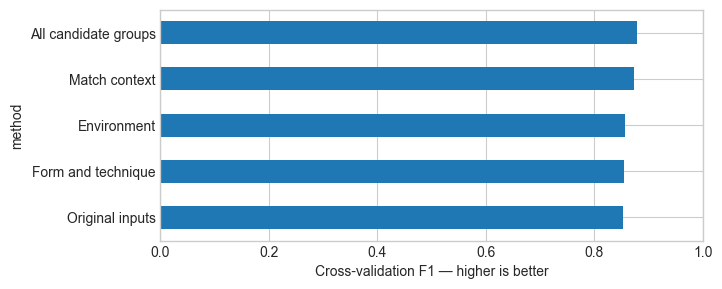

Continue with: All candidate groups


In [15]:
results = compare(models, X, y)
display(results.round(4))
results.set_index("method")["F1"].sort_values().plot.barh(figsize=(7, 3))
plt.xlabel("Cross-validation F1 — higher is better")
plt.xlim(0, 1)
plt.show()
print("Continue with:", results.iloc[0]["method"])

In [16]:
example = add_features(X.head())
display(example[["player_last5_scored_percent", "goalkeeper_last5_saved_percent", "skill_gap", "form_ratio"]])
display(example[["minute_taken", "current_score_diff", "late_close_game", "skill_under_pressure"]])
display(example[["pitch_condition", "weather_humidity", "poor_pitch", "humidity_weak_foot", "log_capacity"]])
added = example.columns.difference(X.columns)
print("New candidates:", len(added))

,player_last5_scored_percent,goalkeeper_last5_saved_percent,skill_gap,form_ratio
0,60,80,-20,0.753
1,0,80,-80,0.012
2,80,60,20,1.328
3,60,0,60,61.000
4,80,80,0,1.000


,minute_taken,current_score_diff,late_close_game,skill_under_pressure
0,38.0,1,0,0
1,31.0,2,0,0
2,82.0,-2,0,0
3,83.0,2,0,0
4,21.0,1,0,0


,pitch_condition,weather_humidity,poor_pitch,humidity_weak_foot,log_capacity
0,Excellent,51.0,0,0.162,10.986
1,Excellent,88.0,0,0.376,11.109
2,Good,35.0,0,0.064,10.569
3,Excellent,85.0,0,0.345,NaN
4,Good,94.0,0,0.330,10.879


New candidates: 20


**Other alternatives:** bins group minutes into ranges (simple, but lose detail); polynomial expansion
generates many squares/products automatically (can explode in size); historical player averages need
real past-only records and training-only fitting. We do not manufacture player histories from IDs.

## 9. Results and decision

| Question | Answer |
|---|---|
| What did we compare? | Original inputs, six form/technique features, eight context features, six environment features, and all 20 together. |
| Which performed best? | All candidate groups — mean CV F1 0.8780 (rounded saved result). |
| Why did we choose it? | The input-only form, context, and environment candidates work best together in this comparison. |
| What are its limitations? | Twenty candidates add complexity; some may be redundant. Sounding plausible is not evidence of causality or predictive value. |
| What continues to the next notebook? | All 20 candidate features; later selection may remove weak columns. |

## 10. Key takeaways and next step

- A useful feature expresses an input-only hypothesis and improves unseen-row predictions.
- More features are candidates, not guaranteed improvements.

Next: [06 Feature Selection](06_Feature_Selection.ipynb).